# DSA 107 — Lab 1: Environment and first notebook

**Week 2 · 30 September 2026** · paired with DSA 101 lecture week 2

**Name:** Esma Nur Özgökçe  **Student ID:** 240219019005

---

### What you will produce

A runnable Colab notebook, pushed to your own GitHub repository, that loads a dataset, answers four questions about it, and draws one labelled figure.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn scikit-learn` in a new cell and try again.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


## 1. Load the data

`pd.read_csv` accepts a URL as happily as a filename. Load the penguins dataset into a DataFrame called `penguins`.

In [26]:
penguins = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv")

# TODO: show the first five rows
#penguins.head(10),when we write 10 into the paranthesis,this code displays the first 10 rows of the dataset
penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 2. How big is it, and what is in it?

Three commands answer almost every first question about a dataset:

- `.shape` — rows and columns
- `.info()` — column names, types, and how many non-missing values each has
- `.describe()` — summary statistics for the numeric columns

In [40]:
# TODO: print the shape, then call .info()
print(penguins.shape)
penguins.info()
#penguins.describe().T,Applying `.T` (transpose) to `penguins.describe()` flips the summary table so that feature variables appear as rows.

(344, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [28]:
# TODO: summary statistics for the numeric columns
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


### Missing values

`.isna()` gives a True/False table the same shape as the data. Summing it down the columns counts the missing values in each.

In [29]:
# TODO: count the missing values in each column
penguins.isna().sum()


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


**Q1.** How many penguins are in the dataset, and how many columns describe each one?

**Q2.** Which column has the most missing values, and how many? Suggest one plausible reason a field measurement might be missing.

Answer of **Q1.** There are 344 penguins in the dataset, and each penguin is described by 7 columns.

Answer of **Q2.** The sex column has the most missing values, with 11 missing entries.A plausible reason for missing field measurements could be that the penguin escaped before all physical measurements  or environmental conditions made it difficult.

## 3. Selecting and filtering

A single column is `df["name"]`. Several columns is `df[["a", "b"]]` — note the double brackets. Rows are chosen with a condition: `df[df["col"] > 5]`.

In [30]:
# TODO: show only species, island and body_mass_g, first five rows
penguins[["species", "island", "body_mass_g"]].head()

,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0


In [31]:
# TODO: make a DataFrame called gentoo holding only the Gentoo penguins,
# then print how many there are
gentoo = penguins[penguins["species"] == "Gentoo"]
print(len(gentoo))

124


**Q3.** How many Gentoo penguins are there? What fraction of the dataset is that?

Answer of **Q3.** There are 124 Gentoo penguins in the dataset, which represents 0.3605  of the total dataset.

In [32]:
# TODO: compute and print the fraction
#total_count = len(penguins)
#gentoo_count = len(gentoo)
fraction = len(gentoo) / len(penguins)
print(fraction)

0.36046511627906974


## 4. Your first figure

A scatter plot of two numeric columns, coloured by a third categorical one. Every figure in this course needs axis labels and a title — a plot without them is not a finished piece of work.

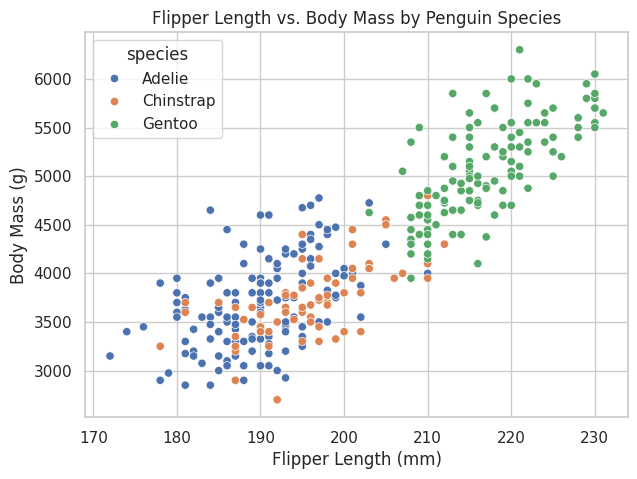

In [38]:
fig, ax = plt.subplots(figsize=(7, 5))
# TODO: scatter plot of flipper_length_mm against body_mass_g,
#       coloured by species, with labels and a title
sns.scatterplot(
    data=penguins,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    ax=ax
)

ax.set_title("Flipper Length vs. Body Mass by Penguin Species")
ax.set_xlabel("Flipper Length (mm)")
ax.set_ylabel("Body Mass (g)")

plt.show()

**Q4.** Describe the relationship in two sentences. Does it hold within every species, or only across all three together? What would you check next?

Answer of **Q4.** There is a positive linear relationship between flipper length and body mass, meaning penguins with longer flippershave greater body mass. This positive relationship holds both overall and within each individual species, though Gentoo penguins are larger. Next, I would check if this relationship varies by sex or island within each species.

## 5. Push to GitHub

1. Create a repository named `dsa107-labs` on GitHub (public is fine).
2. In Colab: **File → Save a copy in GitHub**, choose that repository.
3. Paste the resulting link in the cell below.

**Repository link:**https://github.com/esmaozgokce2006-droid/dsa107-labs.git

---

## Submission checklist

- [x] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [x] Every written answer is filled in — a plot with no reading of it scores zero on interpretation
- [x] Notebook saved as `Lab01_Firstname_Lastname.ipynb`
- [x] Report exported as `Lab01_Firstname_Lastname.pdf`
- [x] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.

1)There are 124 Gentoo penguins in the dataset, which represents approximately 0.3605 (or 36.05%) of the total dataset. I cant understand this mention.
-The value 0.3605 is the fraction of Gentoo penguins in the dataset. It was calculated by dividing the number of Gentoo penguins (124) by the total number of penguins (344). This means that approximately 36.05% of the penguins in the dataset are Gentoo penguins.


2)https://colab.research.google.com/drive/1Q-DHFRhNwAMOBMnY5T4TETmlLULhWB-G#scrollTo=453583c0&line=1&uniqifier=1. I cant understand this dataset
The Palmer Penguins dataset contains observations of three different species of penguins (Adelie, Chinstrap, and Gentoo) living on three islands in the Palmer Archipelago, Antarctica.

Here is a simple explanation of what each column in your dataset represents:

species: The specific penguin species (Adelie, Chinstrap, or Gentoo).
island: The specific island in Antarctica where the penguin was observed (Torgersen, Biscoe, or Dream).
bill_length_mm: The length of the penguin's bill (beak) in millimeters.
bill_depth_mm: The depth (thickness) of the penguin's bill in millimeters.
flipper_length_mm: The length of the penguin's flipper (wing) in millimeters.
body_mass_g: The weight of the penguin in grams.
sex: The biological sex of the penguin (MALE or FEMALE).
Essentially, scientists collected this data to study how these different physical characteristics (like body weight, flipper size, and beak shape) differ between species and genders.


Scatter plot'ı `flipper_length_mm` ve `body_mass_g` ile nasıl çizebilirim?
Seaborn kütüphanesini kullanarak flipper_length_mm ve body_mass_g sütunları arasındaki ilişkiyi gösteren, türlere (species) göre renklendirilmiş, başlık ve eksen etiketleri eklenmiş scatter plot kodunu aşağıda hazırladım.

Grafiğiniz başarıyla çizildi! Şimdi son soruyu (Q4) cevaplayabiliriz.

Grafiğe baktığımızda, genel olarak kanat uzunluğu (flipper_length_mm) arttıkça vücut kütlesinin (body_mass_g) de arttığını, yani güçlü ve pozitif bir ilişki olduğunu görüyoruz. Bu ilişki hem genel olarak tüm veri setinde hem de her bir penguen türünün kendi içinde (bireysel kümelerde de yukarı yönlü bir eğilim olarak) geçerlidir.

225793ad numaralı hücreyi bu açıklamalarla güncelledim.


ı want to change this graph colours.
Grafiğin renklerini değiştirmek için palette parametresini kullanabiliriz. Aşağıdaki kodda renkleri değiştirmek için popüler ve canlı bir renk paleti olan "Set2" paletini ekledim. İsterseniz bunu "viridis", "plasma", "muted" veya "bright" gibi diğer hazır paletlerle de değiştirebilirsiniz.


2. aşamada sütunları dikey yapmak istiyosam ne yapmalıyım
Verilerinizi veya özet istatistiklerinizi (2. aşamadaki describe() tablosunu) dikey yapmak (yani satırları sütun, sütunları satır haline getirmek) istiyorsanız Pandas kütüphanesindeki transpoze yöntemini (.T veya .transpose()) kullanabilirsiniz.

Örnek olarak cd52876d hücresindeki penguins.describe() kodunu penguins.describe().T şeklinde güncelledim. Böylece istatistik özetleriniz dikey (yan yana değil, alt alta sütunlar halinde) görünecektir.